# Lab 03 — Trực quan hóa dữ liệu và kết quả mô hình (ít nhất 15 biểu đồ)

Sổ tay này **không định nghĩa lại logic** — nó gọi trực tiếp các mô-đun của Lab 03
(`src/lab03/data.py`, `features.py`, `cv.py`, `lab03_models/*`, `metrics.py`) để vẽ các
biểu đồ minh họa từng giai đoạn: khám phá dữ liệu (EDA), chia dữ liệu, kiểm định chéo,
huấn luyện và so sánh mô hình, chẩn đoán phần dư, mức độ quan trọng của đặc trưng và dự báo 24 giờ.

Dữ liệu: `data/raw/AEP_hourly.csv` (mức tiêu thụ điện theo giờ của PJM, MW). Mọi mô hình là
các lớp tự cài đặt bằng NumPy trong `src/lab03/lab03_models/` (không dùng scikit-learn/xgboost).

In [1]:
import sys, os
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.lab03.utils import load_config, get_path, ensure_directories, set_global_seed
from src.lab03.data import load_hourly_series, chronological_split
from src.lab03.features import build_supervised_features, recursive_forecast
from src.lab03.cv import evaluate_walk_forward
from src.lab03.metrics import regression_metrics
from src.lab03.pipeline import build_model_factories

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                      "axes.titleweight": "bold", "font.size": 10})

%matplotlib inline
cfg = load_config()
set_global_seed(cfg["project"].get("random_seed", 42))
dirs = ensure_directories(cfg)
FIG_DIR = get_path("figures_dir", cfg) / "notebook_visual_exploration"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CHART_COUNT = 0
def save(fig, name):
    """Lưu mọi biểu đồ vào thư mục ảnh và đánh số thứ tự để đối chiếu với yêu cầu ≥ 15 biểu đồ."""
    global CHART_COUNT
    CHART_COUNT += 1
    fig.savefig(FIG_DIR / f"{CHART_COUNT:02d}_{name}.png", dpi=130, bbox_inches="tight")
    print(f"[{CHART_COUNT:02d}] đã lưu: {name}.png")

## 1. Nạp và làm sạch dữ liệu

In [2]:
data_cfg = cfg["data"]
series, meta = load_hourly_series(get_path("data_raw", cfg), timestamp_col=data_cfg["date_col"],
                                   value_col=data_cfg["target_col"], frequency=data_cfg["freq"])
print(f"{meta['observations_after_cleaning']:,} giờ | {meta['start']} -> {meta['end']} | "
      f"trùng đã gộp: {meta['duplicate_timestamps_removed']} | giờ thiếu đã thêm: {meta['missing_periods_inserted']}")
series.describe().round(1)

121,296 giờ | 2004-10-01 01:00:00 -> 2018-08-03 00:00:00 | trùng đã gộp: 4 | giờ thiếu đã thêm: 27


count    121296.0
mean      15499.2
std        2591.4
min        9581.0
25%       13629.0
50%       15309.0
75%       17200.0
max       25695.0
Name: AEP_MW, dtype: float64

## 2. Biểu đồ khám phá dữ liệu (EDA)

[01] đã lưu: hourly_series_overview.png


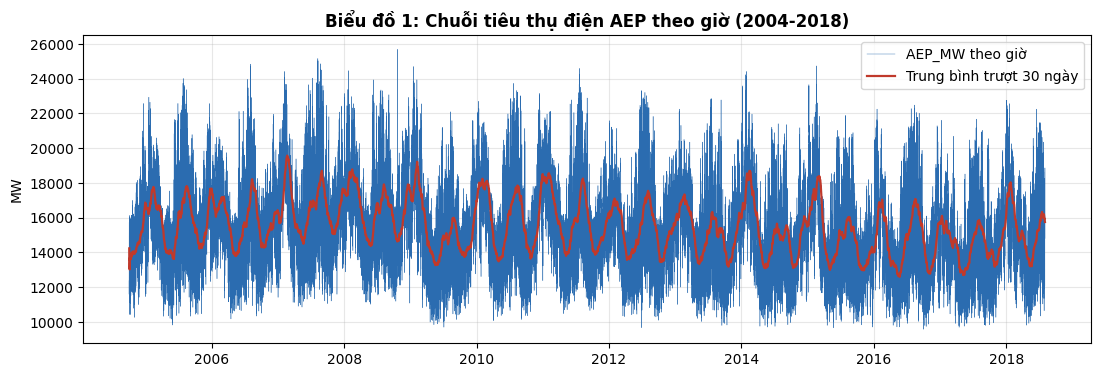

In [3]:
# Biểu đồ 1: Toàn bộ chuỗi + trung bình trượt 30 ngày
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(series.index, series.values, lw=0.3, color="#2b6cb0", label="AEP_MW theo giờ")
ax.plot(series.index, series.rolling(24 * 30, min_periods=24).mean(), lw=1.6, color="#c0392b", label="Trung bình trượt 30 ngày")
ax.set_title("Biểu đồ 1: Chuỗi tiêu thụ điện AEP theo giờ (2004-2018)"); ax.set_ylabel("MW"); ax.legend()
save(fig, "hourly_series_overview"); plt.show()

[02] đã lưu: distribution_histogram.png


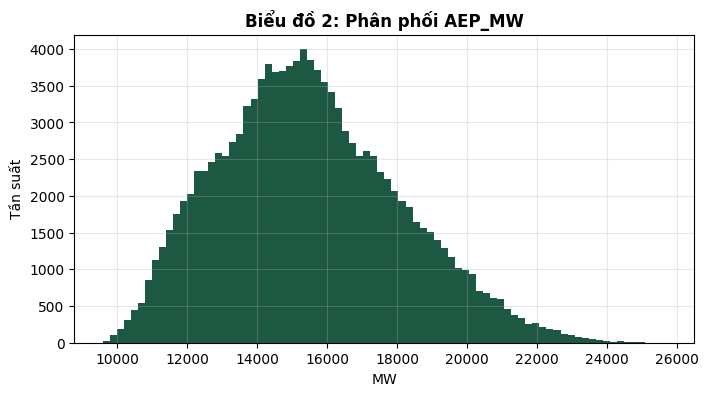

In [4]:
# Biểu đồ 2: Phân phối giá trị tải điện
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(series.values, bins=80, color="#1d5843")
ax.set_title("Biểu đồ 2: Phân phối AEP_MW"); ax.set_xlabel("MW"); ax.set_ylabel("Tần suất")
save(fig, "distribution_histogram"); plt.show()

[03] đã lưu: avg_load_by_hour.png


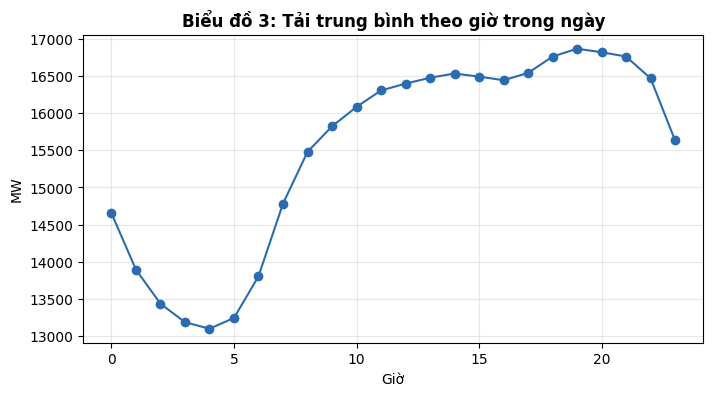

In [5]:
# Biểu đồ 3: Tải trung bình theo giờ trong ngày
hourly_profile = series.groupby(series.index.hour).mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly_profile.index, hourly_profile.values, "o-", color="#2b6cb0")
ax.set_title("Biểu đồ 3: Tải trung bình theo giờ trong ngày"); ax.set_xlabel("Giờ"); ax.set_ylabel("MW")
save(fig, "avg_load_by_hour"); plt.show()

[04] đã lưu: avg_load_by_weekday.png


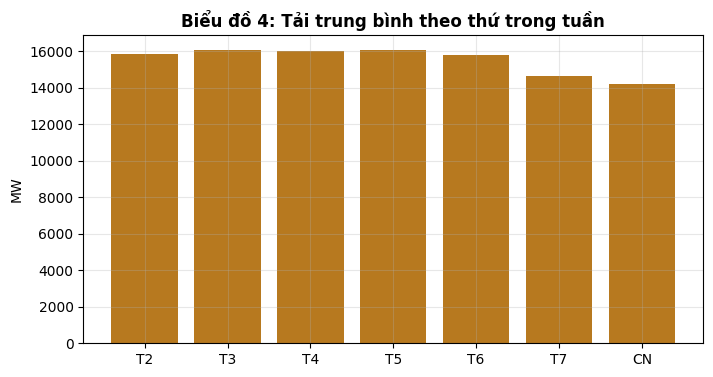

In [6]:
# Biểu đồ 4: Tải trung bình theo thứ trong tuần
dow_profile = series.groupby(series.index.dayofweek).mean()
labels = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, dow_profile.values, color="#b7791f")
ax.set_title("Biểu đồ 4: Tải trung bình theo thứ trong tuần"); ax.set_ylabel("MW")
save(fig, "avg_load_by_weekday"); plt.show()

[05] đã lưu: heatmap_weekday_hour.png


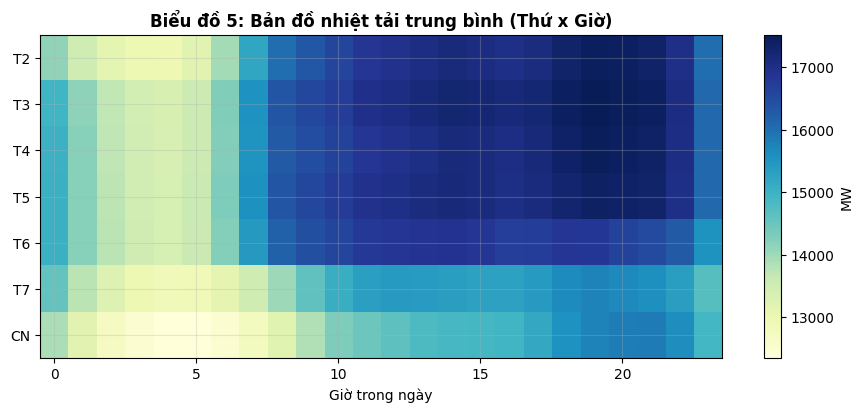

In [7]:
# Biểu đồ 5: Bản đồ nhiệt tải trung bình (thứ x giờ)
pivot = series.groupby([series.index.dayofweek, series.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(7)); ax.set_yticklabels(labels); ax.set_xlabel("Giờ trong ngày")
ax.set_title("Biểu đồ 5: Bản đồ nhiệt tải trung bình (Thứ x Giờ)"); fig.colorbar(im, ax=ax, label="MW")
save(fig, "heatmap_weekday_hour"); plt.show()

[06] đã lưu: monthly_seasonality_boxplot.png


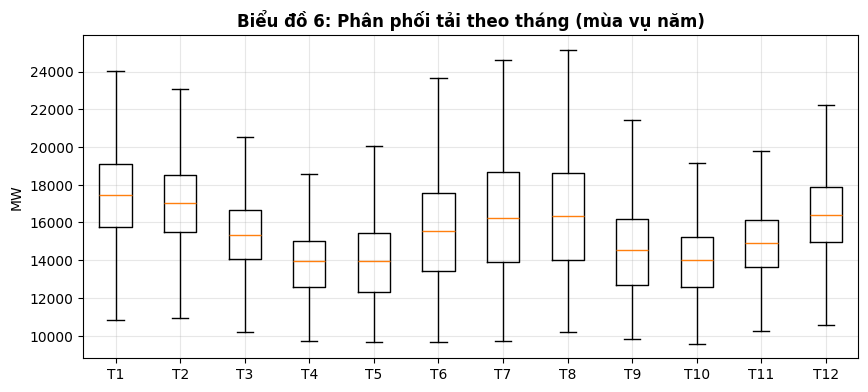

In [8]:
# Biểu đồ 6: Phân phối tải theo tháng (mùa vụ năm)
fig, ax = plt.subplots(figsize=(10, 4.2))
monthly_groups = [series[series.index.month == m].values for m in range(1, 13)]
ax.boxplot(monthly_groups, tick_labels=[f"T{m}" for m in range(1, 13)], showfliers=False)
ax.set_title("Biểu đồ 6: Phân phối tải theo tháng (mùa vụ năm)"); ax.set_ylabel("MW")
save(fig, "monthly_seasonality_boxplot"); plt.show()

[07] đã lưu: acf_plot.png


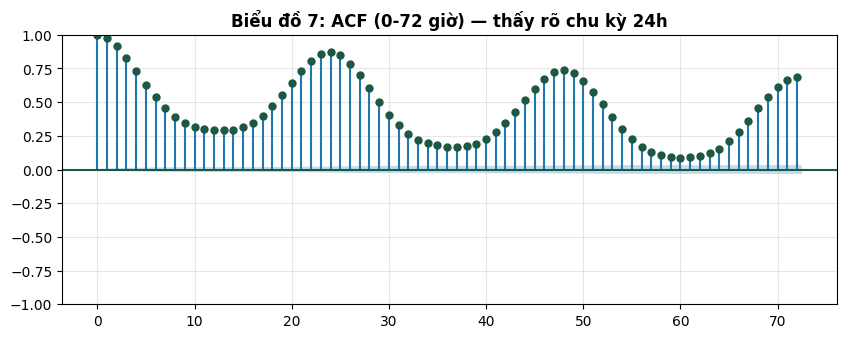

[08] đã lưu: pacf_plot.png


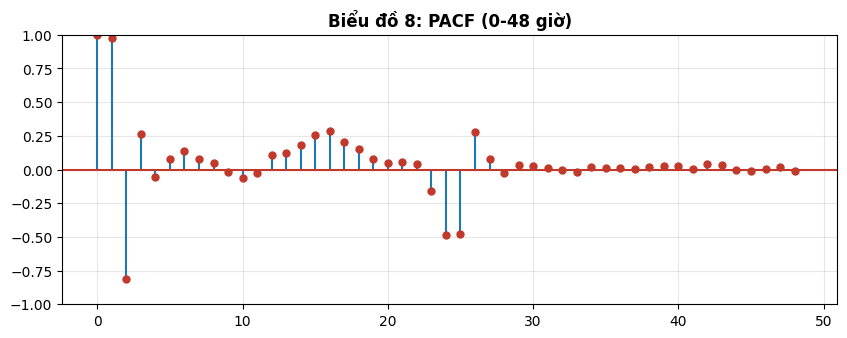

In [9]:
# Biểu đồ 7 & 8: ACF và PACF của chuỗi gốc
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(series.values, lags=72, ax=ax, color="#1d5843")
ax.set_title("Biểu đồ 7: ACF (0-72 giờ) — thấy rõ chu kỳ 24h")
save(fig, "acf_plot"); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
plot_pacf(series.values, lags=48, ax=ax, method="ywm", color="#c0392b")
ax.set_title("Biểu đồ 8: PACF (0-48 giờ)")
save(fig, "pacf_plot"); plt.show()

## 3. Tạo đặc trưng và chia dữ liệu

In [10]:
f_cfg = cfg["features"]
X, y = build_supervised_features(series, lags=tuple(f_cfg["lags"]), rolling_windows=tuple(f_cfg["rolling_windows"]),
                                  include_calendar=f_cfg["include_calendar"])
sp = cfg["preprocessing"]["split"]
X_train, X_val, X_test, y_train, y_val, y_test = chronological_split(X, y, train_ratio=sp["train_ratio"],
                                                                       val_ratio=sp["val_ratio"], test_ratio=sp["test_ratio"])
print(f"X={X.shape} | Huấn luyện={len(X_train)} | Xác thực={len(X_val)} | Kiểm tra={len(X_test)}")

X=(121128, 22) | Huấn luyện=84789 | Xác thực=18169 | Kiểm tra=18170


[09] đã lưu: train_val_test_split.png


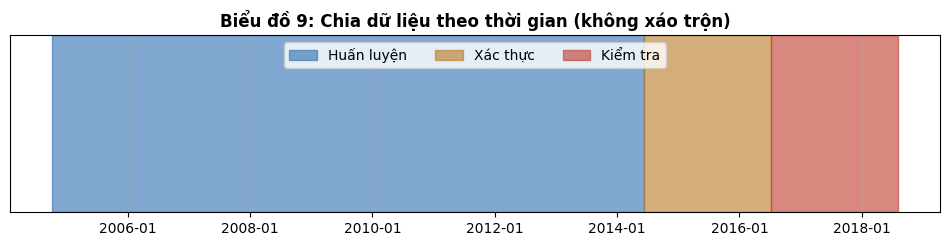

In [11]:
# Biểu đồ 9: Sơ đồ chia Train / Validation / Test theo thời gian
fig, ax = plt.subplots(figsize=(12, 2.3))
for data_part, color, label in [(y_train, "#2b6cb0", "Huấn luyện"), (y_val, "#b7791f", "Xác thực"), (y_test, "#c0392b", "Kiểm tra")]:
    ax.axvspan(data_part.index.min(), data_part.index.max(), color=color, alpha=0.6, label=label)
ax.set_yticks([]); ax.legend(ncol=3, loc="upper center"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Biểu đồ 9: Chia dữ liệu theo thời gian (không xáo trộn)")
save(fig, "train_val_test_split"); plt.show()

[10] đã lưu: lag_correlation.png


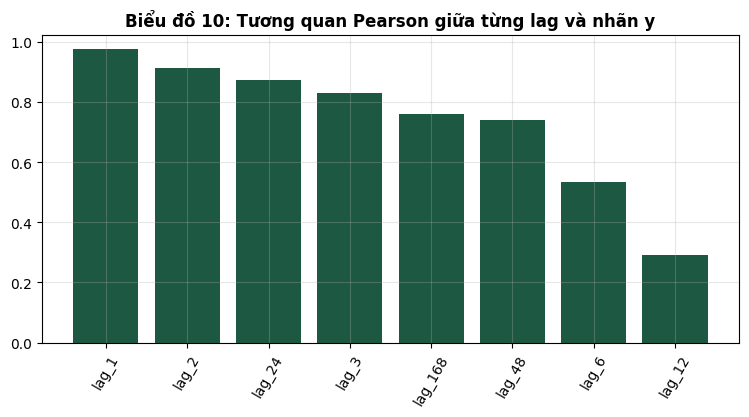

In [12]:
# Biểu đồ 10: Tương quan giữa các lag chính và nhãn y (Pearson)
lag_cols = [c for c in X.columns if c.startswith("lag_")]
corr = X[lag_cols].assign(y=y).corr()["y"].drop("y").sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(corr.index, corr.values, color="#1d5843")
ax.set_title("Biểu đồ 10: Tương quan Pearson giữa từng lag và nhãn y"); ax.tick_params(axis="x", rotation=60)
save(fig, "lag_correlation"); plt.show()

## 4. Kiểm định chéo (5 lượt chia theo cửa sổ mở rộng trên tập huấn luyện)

In [13]:
factories = build_model_factories(cfg)
MODEL_LABELS = {
    "Naive Last-Value": "Giá trị gần nhất",
    "Linear Regression": "Hồi quy tuyến tính",
    "CART": "Cây hồi quy CART",
    "Random Forest": "Rừng ngẫu nhiên",
    "XGBoost-style": "Mô hình tăng cường kiểu XGBoost",
}
n_splits = cfg["preprocessing"]["cross_validation"]["n_splits"]
cv_detail, _ = evaluate_walk_forward(X_train, y_train, factories, n_splits=n_splits)
cv_detail.assign(model=cv_detail["model"].map(MODEL_LABELS)).head()

,fold,model,train_rows,validation_rows,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
0,1,Giá trị gần nhất,14134,14131,479.761234,386287.986059,621.520704,2.994307,2.995055,0.945491
1,1,Hồi quy tuyến tính,14134,14131,209.375356,77912.982771,279.128972,1.287593,1.287523,0.989006
2,1,Cây hồi quy CART,14134,14131,268.876842,127348.319977,356.858964,1.637057,1.639753,0.982030
3,1,Rừng ngẫu nhiên,14134,14131,403.237530,299686.281915,547.436098,2.442187,2.447041,0.957711
4,1,Mô hình tăng cường kiểu XGBoost,14134,14131,625.811968,791448.474169,889.633899,3.744890,3.773831,0.888318


[11] đã lưu: cv_rmse_by_fold.png


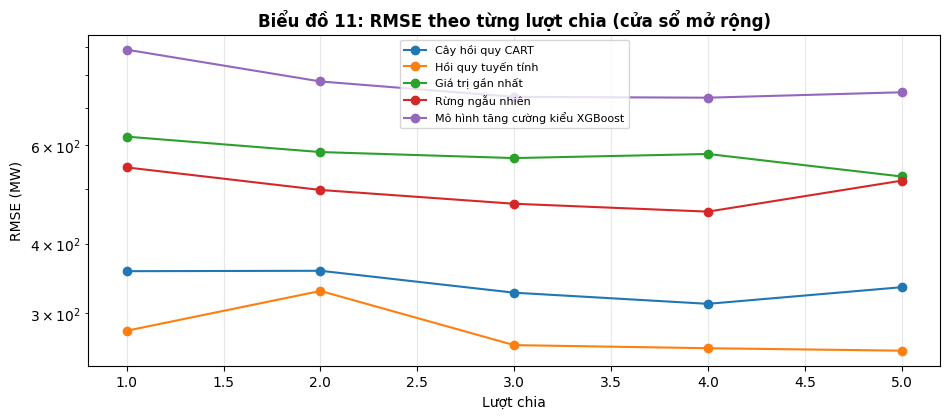

In [14]:
# Biểu đồ 11: RMSE theo từng lượt chia cho mỗi mô hình
fig, ax = plt.subplots(figsize=(11, 4.3))
for name, group in cv_detail.groupby("model"):
    g = group.sort_values("fold")
    ax.plot(g["fold"], g["RMSE"], "o-", label=MODEL_LABELS.get(name, name))
ax.set_xlabel("Lượt chia"); ax.set_ylabel("RMSE (MW)"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("Biểu đồ 11: RMSE theo từng lượt chia (cửa sổ mở rộng)")
save(fig, "cv_rmse_by_fold"); plt.show()

[12] đã lưu: cv_rmse_boxplot.png


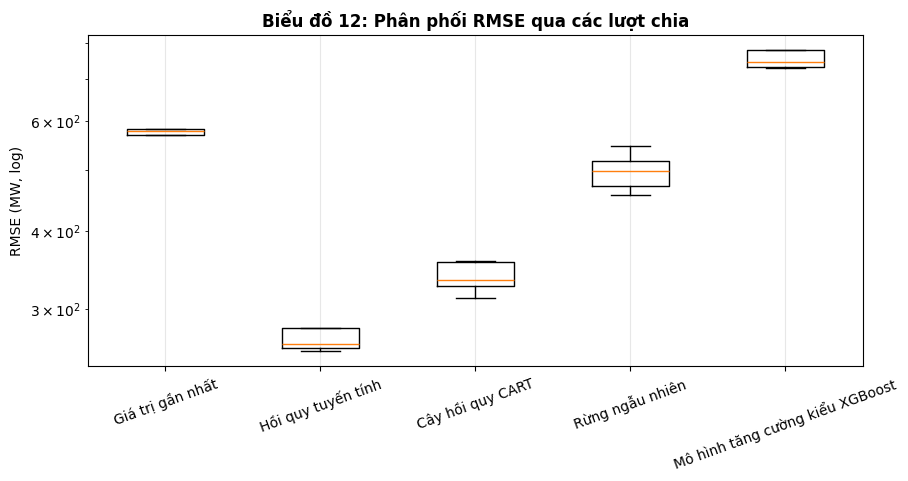

In [15]:
# Biểu đồ 12: Phân phối RMSE qua các lượt chia cho mỗi mô hình
fig, ax = plt.subplots(figsize=(10, 4.3))
order = list(cv_detail["model"].unique())
order_labels = [MODEL_LABELS.get(model, model) for model in order]
ax.boxplot([cv_detail[cv_detail.model == m]["RMSE"].values for m in order], tick_labels=order_labels, showfliers=False)
ax.set_yscale("log"); ax.set_ylabel("RMSE (MW, log)"); ax.tick_params(axis="x", rotation=20)
ax.set_title("Biểu đồ 12: Phân phối RMSE qua các lượt chia")
save(fig, "cv_rmse_boxplot"); plt.show()

## 5. Huấn luyện, chọn mô hình và đánh giá trên tập kiểm tra

In [16]:
validation_rows, test_rows, test_predictions, final_models = [], [], {}, {}
X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
for name, factory in factories.items():
    m = factory(); m.fit(X_train.to_numpy(float), y_train.to_numpy(float))
    validation_rows.append({"model": name, **regression_metrics(y_val, m.predict(X_val.to_numpy(float)))})
for name, factory in factories.items():
    m = factory(); m.fit(X_tv.to_numpy(float), y_tv.to_numpy(float))
    pred = m.predict(X_test.to_numpy(float))
    test_predictions[name] = pred; final_models[name] = m
    test_rows.append({"model": name, **regression_metrics(y_test, pred)})
validation_summary = pd.DataFrame(validation_rows).set_index("model").sort_values("RMSE")
test_summary = pd.DataFrame(test_rows).set_index("model")
champion = validation_summary.index[0]
print("Mô hình tốt nhất (RMSE xác thực thấp nhất):", MODEL_LABELS.get(champion, champion))
validation_summary.rename(index=MODEL_LABELS).round(2)

Mô hình tốt nhất (RMSE xác thực thấp nhất): Hồi quy tuyến tính


,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
model,,,,,,
Hồi quy tuyến tính,181.68,60583.42,246.14,1.24,1.24,0.99
Cây hồi quy CART,249.88,104013.55,322.51,1.71,1.70,0.98
Rừng ngẫu nhiên,389.64,243941.04,493.90,2.74,2.71,0.96
Giá trị gần nhất,413.89,285633.04,534.45,2.85,2.85,0.95
Mô hình tăng cường kiểu XGBoost,610.81,604425.63,777.45,4.48,4.36,0.90


[13] đã lưu: validation_rmse_comparison.png


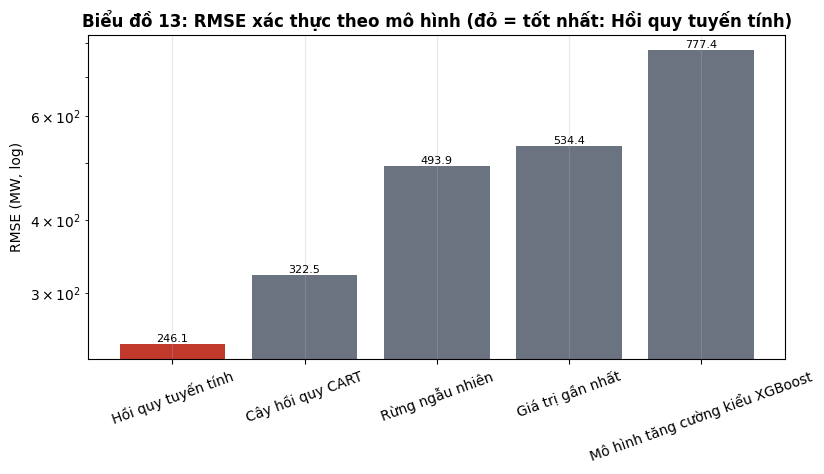

In [17]:
# Biểu đồ 13: So sánh Validation RMSE giữa các mô hình
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["#c0392b" if m == champion else "#6b7280" for m in validation_summary.index]
model_labels = [MODEL_LABELS.get(model, model) for model in validation_summary.index]
bars = ax.bar(model_labels, validation_summary["RMSE"], color=colors)
ax.bar_label(bars, fmt="%.1f", fontsize=8); ax.set_yscale("log"); ax.tick_params(axis="x", rotation=20)
ax.set_title(f"Biểu đồ 13: RMSE xác thực theo mô hình (đỏ = tốt nhất: {MODEL_LABELS.get(champion, champion)})"); ax.set_ylabel("RMSE (MW, log)")
save(fig, "validation_rmse_comparison"); plt.show()

[14] đã lưu: test_metric_comparison.png


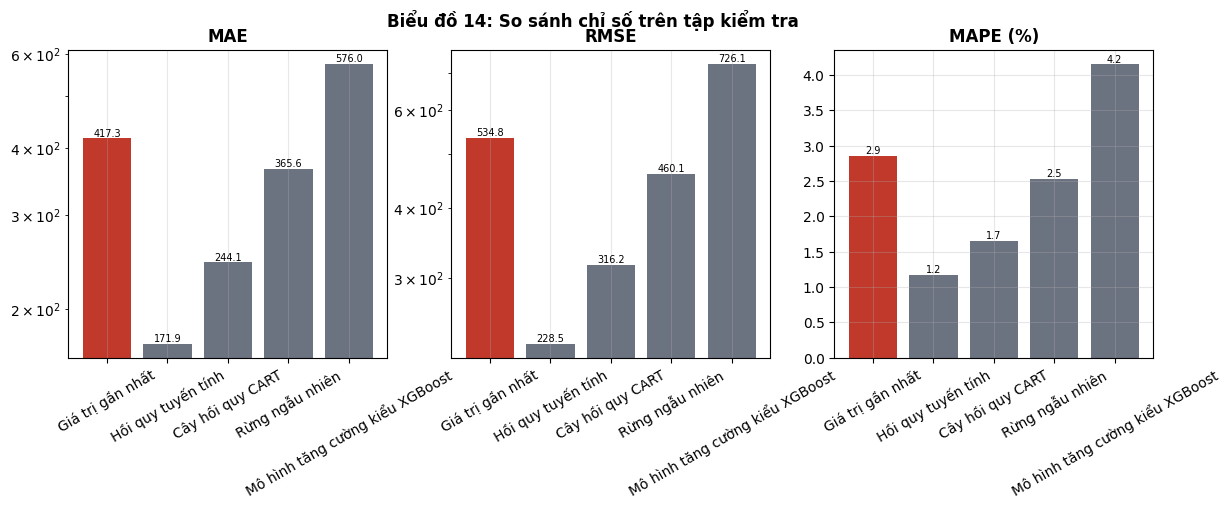

In [18]:
# Biểu đồ 14: So sánh MAE / RMSE / MAPE trên Test cho mọi mô hình
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, metric in zip(ax, ["MAE", "RMSE", "MAPE (%)"]):
    model_labels = [MODEL_LABELS.get(model, model) for model in test_summary.index]
    bars = a.bar(model_labels, test_summary[metric], color=colors)
    a.bar_label(bars, fmt="%.1f", fontsize=7); a.set_title(metric); a.tick_params(axis="x", rotation=30)
    if metric != "MAPE (%)": a.set_yscale("log")
fig.suptitle("Biểu đồ 14: So sánh chỉ số trên tập kiểm tra", fontweight="bold")
save(fig, "test_metric_comparison"); plt.show()

[15] đã lưu: test_forecast_overlay.png


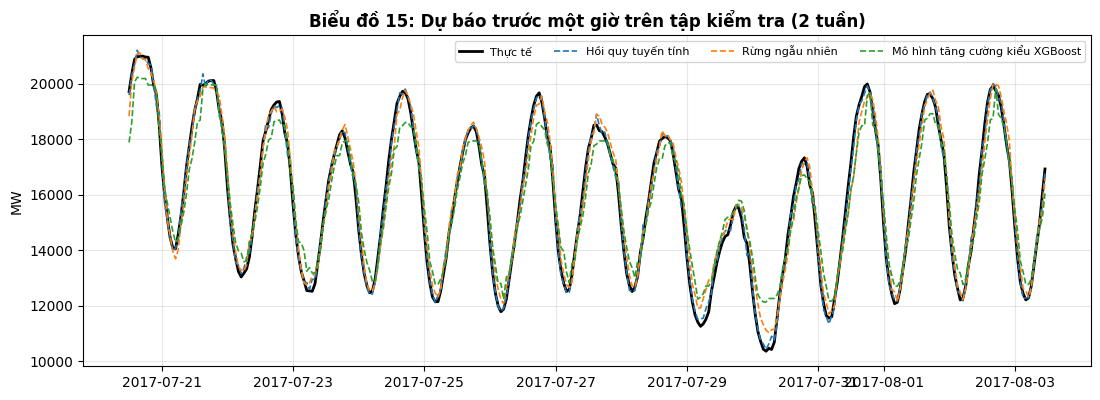

In [19]:
# Biểu đồ 15: Dự báo 1 giờ trước trên Test (2 tuần) - thực tế vs các mô hình
window = test_summary.index
z = slice(len(y_test) // 2, len(y_test) // 2 + 24 * 14)
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.plot(y_test.index[z], y_test.values[z], color="black", lw=2, label="Thực tế")
for name in ["Linear Regression", "Random Forest", "XGBoost-style"]:
    ax.plot(y_test.index[z], test_predictions[name][z], "--", lw=1.2, label=MODEL_LABELS.get(name, name))
ax.set_title("Biểu đồ 15: Dự báo trước một giờ trên tập kiểm tra (2 tuần)"); ax.set_ylabel("MW"); ax.legend(ncol=4, fontsize=8)
save(fig, "test_forecast_overlay"); plt.show()

[16] đã lưu: residual_over_time.png


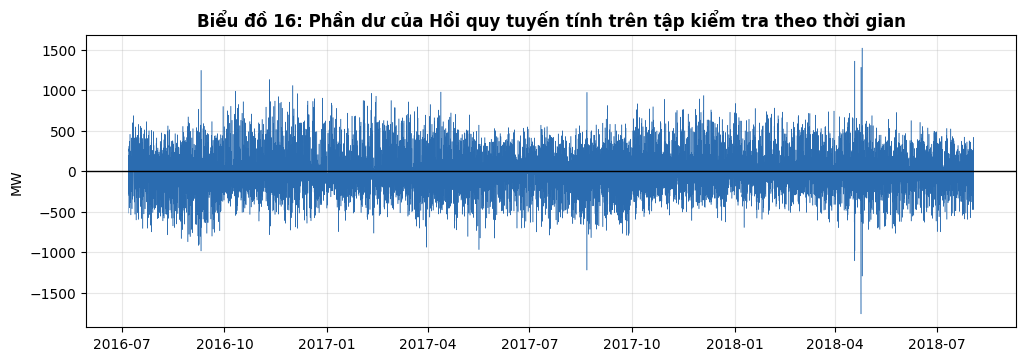

In [20]:
# Biểu đồ 16: Phần dư của champion theo thời gian
residual = y_test.values - test_predictions[champion]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y_test.index, residual, lw=0.35, color="#2b6cb0"); ax.axhline(0, color="black", lw=1)
ax.set_title(f"Biểu đồ 16: Phần dư của {MODEL_LABELS.get(champion, champion)} trên tập kiểm tra theo thời gian"); ax.set_ylabel("MW")
save(fig, "residual_over_time"); plt.show()

[17] đã lưu: residual_distribution.png


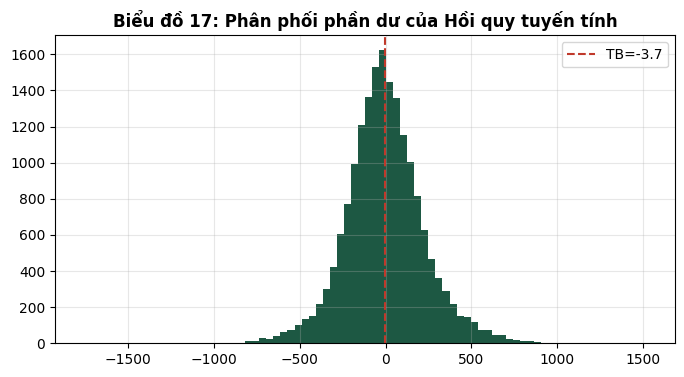

In [21]:
# Biểu đồ 17: Phân phối phần dư của champion
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(residual, bins=80, color="#1d5843")
ax.axvline(residual.mean(), color="#c0392b", ls="--", label=f"TB={residual.mean():.1f}")
ax.set_title(f"Biểu đồ 17: Phân phối phần dư của {MODEL_LABELS.get(champion, champion)}"); ax.legend()
save(fig, "residual_distribution"); plt.show()

[18] đã lưu: feature_importance.png


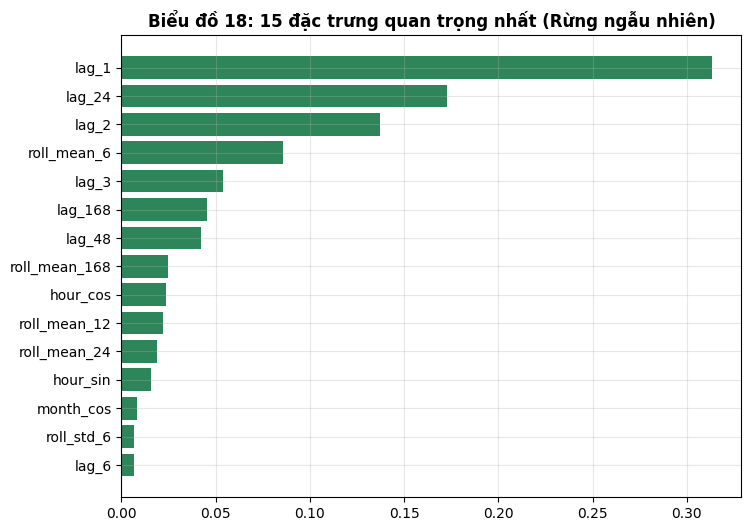

In [22]:
# Biểu đồ 18: Mức độ quan trọng của đặc trưng / hệ số của mô hình diễn giải được
tree_name = "Random Forest" if hasattr(final_models["Random Forest"], "feature_importances_") else None
fig, ax = plt.subplots(figsize=(8, 6))
if tree_name:
    imp = pd.Series(final_models[tree_name].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
    ax.barh(imp.index[::-1], imp.values[::-1], color="#2f855a")
    ax.set_title(f"Biểu đồ 18: 15 đặc trưng quan trọng nhất ({MODEL_LABELS.get(tree_name, tree_name)})")
else:
    coef = pd.Series(final_models["Linear Regression"].coef_, index=X.columns).abs().sort_values(ascending=False).head(15)
    ax.barh(coef.index[::-1], coef.values[::-1], color="#2b6cb0")
    ax.set_title("Biểu đồ 18: 15 hệ số có trị tuyệt đối lớn nhất (Hồi quy tuyến tính)")
save(fig, "feature_importance"); plt.show()

## 6. Suy luận: dự báo 24 giờ tiếp theo

In [23]:
horizon = cfg["forecast"]["horizon_hours"]
forecast_model = factories[champion]()
forecast_model.fit(X.to_numpy(float), y.to_numpy(float))
forecast = recursive_forecast(forecast_model, series, horizon=horizon, feature_names=X.columns,
                               lags=tuple(f_cfg["lags"]), rolling_windows=tuple(f_cfg["rolling_windows"]),
                               include_calendar=f_cfg["include_calendar"])
forecast.head()

2018-08-03 01:00:00    13910.866905
2018-08-03 02:00:00    13252.218415
2018-08-03 03:00:00    12739.503999
2018-08-03 04:00:00    12380.823335
2018-08-03 05:00:00    12304.680885
Name: forecast, dtype: float64

[19] đã lưu: future_24h_forecast.png


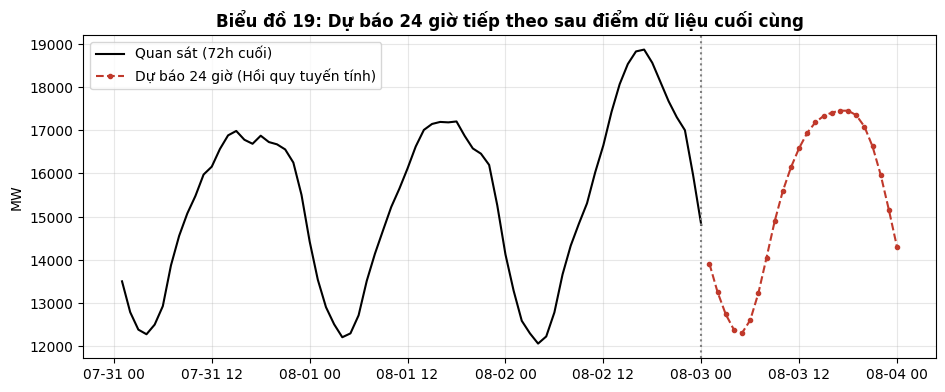

In [24]:
# Biểu đồ 19: 72 giờ quan sát cuối + dự báo đệ quy 24 giờ tiếp theo
fig, ax = plt.subplots(figsize=(11, 4.2))
tail = series.iloc[-72:]
ax.plot(tail.index, tail.values, color="black", label="Quan sát (72h cuối)")
ax.plot(forecast.index, forecast.values, "--", color="#c0392b", marker="o", ms=3, label=f"Dự báo {horizon} giờ ({MODEL_LABELS.get(champion, champion)})")
ax.axvline(series.index[-1], color="grey", ls=":")
ax.set_title("Biểu đồ 19: Dự báo 24 giờ tiếp theo sau điểm dữ liệu cuối cùng"); ax.set_ylabel("MW"); ax.legend()
save(fig, "future_24h_forecast"); plt.show()

## Tổng kết

Sổ tay đã tạo **19 biểu đồ** (đạt yêu cầu tối thiểu 15 biểu đồ), lưu đầy đủ dưới
`reports/lab03/notebook_runs/notebook_visual_exploration/` với tên tệp đánh số `01_...png` đến `19_...png`:
1–8: khám phá dữ liệu (chuỗi gốc, phân phối, hồ sơ giờ/thứ, bản đồ nhiệt, mùa vụ, ACF, PACF);
9–10: chia dữ liệu và tương quan đặc trưng;
11–12: kiểm định chéo;
13–14: so sánh mô hình trên tập xác thực và tập kiểm tra;
15–17: dự báo và phần dư trên tập kiểm tra;
18: mức độ quan trọng của đặc trưng;
19: dự báo 24 giờ tiếp theo.

Mọi số liệu đều lấy từ các mô-đun của Lab 03 (`src/lab03/`), không dùng dữ liệu mô phỏng.